## 미세먼지 경보 데이터로 머신러닝 실습

> - **분류**: "이 미세먼지 경보, 주의보인가? 경보인가?" → 카테고리 예측
> - **회귀**: "발령 당시 미세먼지 농도가 얼마였을까?" → 숫자 예측

**사용 데이터**: `finedust_2020_2025.csv` (공공데이터 포털)
미세먼지 경보 발령 기록 

## 데이터 소개 & 문제 정의

### 미세먼지 경보 시스템

한국 환경부는 미세먼지 농도가 일정 기준을 넘으면 경보를 발령합니다.

```
PM2.5 (초미세먼지):
  주의보 → 시간 평균 농도 ≥ 75 ㎍/㎥  (2시간 이상 지속)
  경  보 → 시간 평균 농도 ≥ 150 ㎍/㎥  (2시간 이상 지속)

PM10 (미세먼지):
  주의보 → 시간 평균 농도 ≥ 150 ㎍/㎥
  경  보 → 시간 평균 농도 ≥ 300 ㎍/㎥
```

### 데이터 컬럼 설명

| 컬럼 | 설명 | 예시 |
|------|------|------|
| `districtName` | 시·도명 | 서울, 경기, 충북 |
| `dataDate` | 발령일 | 2020-12-29 |
| **`issueVal`** | **발령 당시 농도 (㎍/㎥)** ← **회귀 타깃** | 77 |
| `issueTime` | 발령 시각 | 13:00 |
| **`issueGbn`** | **주의보/경보** ← **분류 타깃** | 주의보 |
| `clearVal` | 해제 당시 농도 (㎍/㎥) | 33 |
| `clearTime` | 해제 시각 | 19:00 |
| `clearDate` | 해제일 | 2020-12-29 |
| `itemCode` | 오염물질 종류 | PM10, PM25 |
| `moveName` | 권역명 (세부 지역) | 중부권역 |
| `sn` | 일련번호 (분석 불필요) | 323 |

### 같은 데이터 → 두 가지 ML 문제

```
        발령일   지역    발령농도    해제농도   오염물질   결과
        ───────────────────────────────────────────────────────
데이터:  2020-12  경기    77 ㎍/㎥   33 ㎍/㎥   PM25      주의보

분류 문제: 이 발령은 주의보인가 경보인가?  →  "주의보"  (범주)
회귀 문제: 발령 당시 농도는 얼마인가?   →  77.0     (숫자)
```

> **핵심**: 분류는 '어느 그룹?', 회귀는 '얼마?'
> 같은 데이터에서 타깃을 무엇으로 정하느냐에 따라 문제가 달라집니다.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 분류 모델
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# 회귀 모델
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# 평가 지표
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

plt.rc('font', family='Malgun Gothic')
plt.rc('axes', unicode_minus=False)


## 탐색적 데이터 분석 (EDA)

**EDA 순서 예**
1. 데이터 로드 & 기본 정보
2. 결측값 확인
3. 분류 타깃 분포 (주의보 vs 경보)
4. 시도별 발령 현황
5. 연도별·월별 발령 트렌드
6. PM10 vs PM25 비교
7. 발령 농도 분포


In [2]:
df = pd.read_csv('finedust_2020_2025.csv')
df

,clearVal,sn,districtName,dataDate,issueVal,issueTime,clearDate,issueDate,moveName,clearTime,issueGbn,itemCode
0,33,323,충북,2020-12-29,77,13:00,2020-12-29,2020-12-29,중부권역,19:00,주의보,PM25
1,33,322,세종,2020-12-29,80,12:00,2020-12-29,2020-12-29,세종권역,19:00,주의보,PM25
2,34,320,대구,2020-12-28,83,14:00,2020-12-28,2020-12-28,대구권역,16:00,주의보,PM25
3,28,321,충남,2020-12-28,76,21:00,2020-12-29,2020-12-28,북부권역,22:00,주의보,PM25
4,26,318,대구,2020-12-24,80,11:00,2020-12-24,2020-12-24,대구권역,15:00,주의보,PM25
...,...,...,...,...,...,...,...,...,...,...,...,...
2734,32,5,인천,2025-01-06,78,14:00,2025-01-06,2025-01-06,동남부권역,19:00,주의보,PM25
2735,30,3,인천,2025-01-06,84,14:00,2025-01-06,2025-01-06,강화권역,19:00,주의보,PM25
2736,34,2,인천,2025-01-06,86,13:00,2025-01-06,2025-01-06,영종·영흥권역,18:00,주의보,PM25
2737,21,1,제주,2025-01-06,81,10:00,2025-01-06,2025-01-06,제주권역,14:00,주의보,PM25


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2739 entries, 0 to 2738
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   clearVal      2739 non-null   int64
 1   sn            2739 non-null   int64
 2   districtName  2739 non-null   str  
 3   dataDate      2739 non-null   str  
 4   issueVal      2739 non-null   int64
 5   issueTime     2739 non-null   str  
 6   clearDate     2739 non-null   str  
 7   issueDate     2739 non-null   str  
 8   moveName      2739 non-null   str  
 9   clearTime     2739 non-null   str  
 10  issueGbn      2739 non-null   str  
 11  itemCode      2739 non-null   str  
dtypes: int64(3), str(9)
memory usage: 445.9 KB


In [4]:
df.isnull().sum()

clearVal        0
sn              0
districtName    0
dataDate        0
issueVal        0
issueTime       0
clearDate       0
issueDate       0
moveName        0
clearTime       0
issueGbn        0
itemCode        0
dtype: int64

In [5]:
df.describe().round(2)

,clearVal,sn,issueVal
count,2739.00,2739.00,2739.0
mean,101.53,597.75,174.4
std,110.51,838.13,113.3
min,6.00,1.00,46.0
25%,32.00,126.50,84.0
50%,84.00,270.00,154.0
75%,98.00,609.50,205.0
max,896.00,3542.00,1005.0


In [6]:
df.columns

Index(['clearVal', 'sn', 'districtName', 'dataDate', 'issueVal', 'issueTime',
       'clearDate', 'issueDate', 'moveName', 'clearTime', 'issueGbn',
       'itemCode'],
      dtype='str')

In [7]:
df['issueGbn'].value_counts()

issueGbn
주의보    2433
경보      306
Name: count, dtype: int64

<Axes: ylabel='Frequency'>

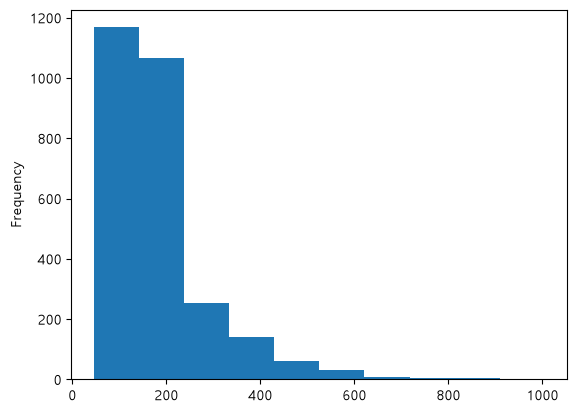

In [8]:
df['issueVal'].plot(kind = 'hist')

<Axes: xlabel='issueVal', ylabel='Count'>

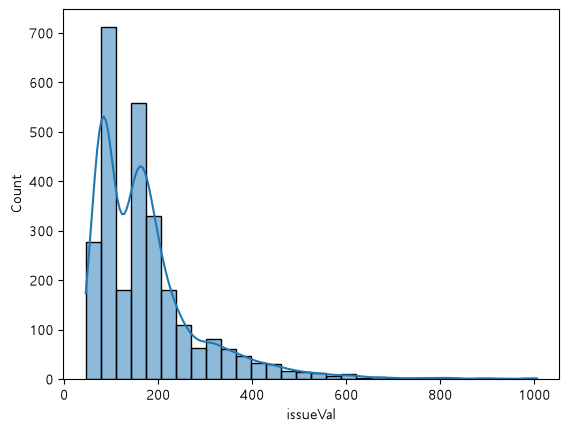

In [9]:
sns.histplot(data = df, x = 'issueVal', bins = 30, kde = True)

In [10]:
df['issueDate']

0       2020-12-29
1       2020-12-29
2       2020-12-28
3       2020-12-28
4       2020-12-24
           ...    
2734    2025-01-06
2735    2025-01-06
2736    2025-01-06
2737    2025-01-06
2738    2025-01-06
Name: issueDate, Length: 2739, dtype: str

In [11]:
df['issueDate'] = pd.to_datetime(df['issueDate'])

In [12]:
df['year'] = df['issueDate'].dt.year

In [13]:
df['month'] = df['issueDate'].dt.month

In [14]:
df.columns

Index(['clearVal', 'sn', 'districtName', 'dataDate', 'issueVal', 'issueTime',
       'clearDate', 'issueDate', 'moveName', 'clearTime', 'issueGbn',
       'itemCode', 'year', 'month'],
      dtype='str')

In [15]:
X = df[['clearVal', 'issueVal', 'itemCode', 'year', 'month']]
X

,clearVal,issueVal,itemCode,year,month
0,33,77,PM25,2020,12
1,33,80,PM25,2020,12
2,34,83,PM25,2020,12
3,28,76,PM25,2020,12
4,26,80,PM25,2020,12
...,...,...,...,...,...
2734,32,78,PM25,2025,1
2735,30,84,PM25,2025,1
2736,34,86,PM25,2025,1
2737,21,81,PM25,2025,1


In [16]:
X = pd.get_dummies(X)

In [17]:
y = df['issueGbn']

In [18]:
X_train, X_test, y_train, y_test = train_test_split( X, y,
            test_size=0.2,
            random_state=0,
            stratify=y
) #stratify=y는 train_test_split()에서 주의보/경보 비율을 유지하면서 데이터를 나누는 옵션, 분류에서 사용

In [26]:
# sklearn 모델 출력 인코딩 에러 방지
import sklearn
sklearn.set_config(display='text')

In [27]:
rf = RandomForestClassifier(random_state = 0)
rf

RandomForestClassifier(random_state=0)

In [28]:
rf.fit(X_train, y_train)

RandomForestClassifier(random_state=0)

In [29]:
y_pred = rf.predict(X_test)

In [30]:
confusion_matrix(y_test, y_pred)

array([[ 59,   2],
       [  1, 486]])

<Axes: >

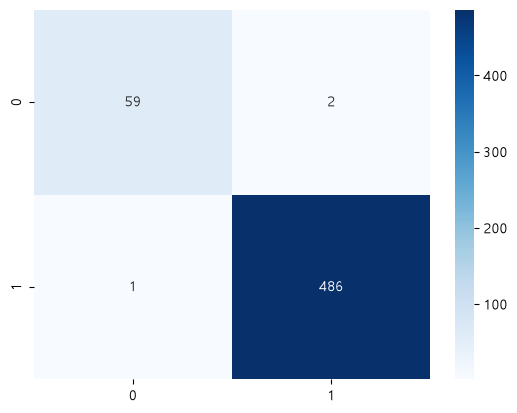

In [31]:
sns.heatmap(confusion_matrix(y_test, y_pred), annot = True, fmt = '.0f', cmap = 'Blues')

- sklearn은 가나다 순(사전순) 으로 인코딩합니다. 따라서 0 = 경보 1 = 주의보

In [32]:
df['issueGbn'].value_counts()

issueGbn
주의보    2433
경보      306
Name: count, dtype: int64

In [35]:
acc_rf = accuracy_score(y_test, y_pred)
precision_rf = precision_score(y_test, y_pred, pos_label = '경보')
recall_rf = recall_score(y_test, y_pred, pos_label = '경보')
f1_rf = f1_score(y_test, y_pred, pos_label = '경보')
print(f'정확도 (Accuracy): {acc_rf:.2f}')
print(f'정밀도 (Precision): {precision_rf:.2f}')
print(f'재현율 (Recall): {recall_rf:.2f}')
print(f'f1-score: {f1_rf:.2f}')

정확도 (Accuracy): 0.99
정밀도 (Precision): 0.98
재현율 (Recall): 0.97
f1-score: 0.98


## 회귀 (Regression) — 발령 농도(issueVal) 예측

> **특성에서 issueVal 제외**     
> 회귀의 타깃이 `issueVal`이므로, 특성으로 `issueVal`을 쓰면       
> "답을 보고 시험 치는 것" (데이터 누수, Data Leakage)!       
> `clearVal`(해제 농도)은 발령 이후 정보지만 교육 목적으로 사용합니다    

In [36]:
df.columns

Index(['clearVal', 'sn', 'districtName', 'dataDate', 'issueVal', 'issueTime',
       'clearDate', 'issueDate', 'moveName', 'clearTime', 'issueGbn',
       'itemCode', 'year', 'month'],
      dtype='str')

In [37]:
X = df[['clearVal', 'itemCode', 'year', 'month']]
X

,clearVal,itemCode,year,month
0,33,PM25,2020,12
1,33,PM25,2020,12
2,34,PM25,2020,12
3,28,PM25,2020,12
4,26,PM25,2020,12
...,...,...,...,...
2734,32,PM25,2025,1
2735,30,PM25,2025,1
2736,34,PM25,2025,1
2737,21,PM25,2025,1


In [38]:
X = pd.get_dummies(X)
X

,clearVal,year,month,itemCode_PM10,itemCode_PM25
0,33,2020,12,False,True
1,33,2020,12,False,True
2,34,2020,12,False,True
3,28,2020,12,False,True
4,26,2020,12,False,True
...,...,...,...,...,...
2734,32,2025,1,False,True
2735,30,2025,1,False,True
2736,34,2025,1,False,True
2737,21,2025,1,False,True


In [39]:
y = df['issueVal']

In [40]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 0)

In [41]:
rf = RandomForestRegressor(random_state = 0)
rf

RandomForestRegressor(random_state=0)

In [42]:
rf.fit(X_train, y_train)

RandomForestRegressor(random_state=0)

In [43]:
y_pred = rf.predict(X_test)

In [46]:
mae_rf = mean_absolute_error(y_test, y_pred)
rmse_rf = root_mean_squared_error(y_test, y_pred)
r2_rf = r2_score(y_test, y_pred)

print(f'평균절대오차 (MAE): {mae_rf:.2f}')
print(f'평균제곱근오차 (RMSE): {rmse_rf:.2f}')
print(f'R2 Score: {r2_rf:.2f}')

평균절대오차 (MAE): 30.40
평균제곱근오차 (RMSE): 54.70
R2 Score: 0.74
